In [6]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
print("ML environment ready")
dataset = pd.read_csv("C:/Users/hp/Downloads/archive (1)/insurance.csv")
df = dataset
print(df.shape)
df.head()

ML environment ready
(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [10]:
X = df.drop(columns=["charges"]) 
y = df["charges"] 
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

X shape: (1338, 6)
y shape: (1338,)
   age     sex     bmi  children smoker     region
0   19  female  27.900         0    yes  southwest
1   18    male  33.770         1     no  southeast
2   28    male  33.000         3     no  southeast
3   33    male  22.705         0     no  northwest
4   32    male  28.880         0     no  northwest


In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42 
)
print(X_train.shape)
print(X_test.shape)

(1070, 6)
(268, 6)


In [14]:
from sklearn.linear_model import LinearRegression 
X1 = X[["age"]]
Xtr, Xte, ytr, yte = train_test_split(
    X1, y, test_size=0.2, random_state=42
)
simple = LinearRegression()
simple.fit(Xtr, ytr)
pred = simple.predict(Xte)
print("Slope:", simple.coef_[0])
print("Intercept:", simple.intercept_)
print("First 5 predictions:", pred[:5])

Slope: 240.59655978877487
Intercept: 3876.928684191693
First 5 predictions: [14703.77387469 12538.40483659 19275.10851067 14944.37043448
  8448.26332018]


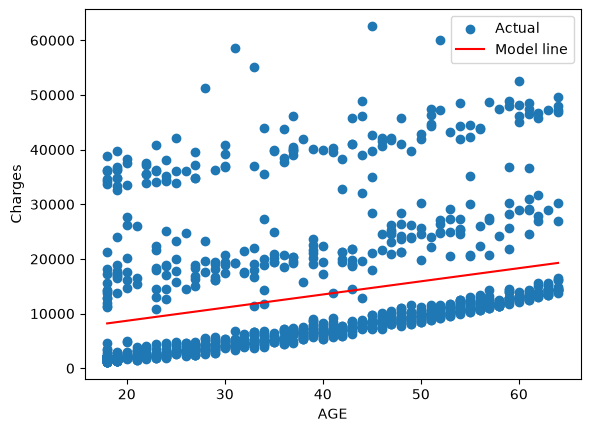

In [17]:
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["age"].values)
plt.scatter(Xtr["age"], ytr, label="Actual")
plt.plot(
    Xtr["age"].values[order],
    pred_train[order],
    color="red",
    label="Model line" 
)
plt.xlabel("AGE")
plt.ylabel("Charges")
plt.legend()
plt.show()

In [20]:
from sklearn.metrics import mean_squared_error 
mse = mean_squared_error(y_test,Xte) 
print("MSE:", mse)

MSE: 322299325.17602015


In [21]:
from sklearn.metrics import (
mean_absolute_error,
mean_squared_error,
r2_score
)
mae = mean_absolute_error(y_test, Xte)
mse = mean_squared_error(y_test, Xte)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, Xte)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 12929.70885391418
MSE: 322299325.17602015
RMSE: 17952.69687751732
R2: -1.0760190571547348
